<a href="https://colab.research.google.com/github/ramahhdk87654321-bit/AI_LAB_PROJECT/blob/main/AI_LAB_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Importing libraries**

In [12]:
!pip install gradio -q

In [13]:
# General
import re
import warnings
from collections import Counter

# Data
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Progress bar + Demo
from tqdm import tqdm
import gradio as gr

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


# **Loading the Dataset**

In [14]:
df = pd.read_csv("/home/IMDB-Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


# **Exploratory Data Analysis (EDA)**

In [15]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicated rows:", df.duplicated().sum())

Shape: (50000, 2)
Columns: ['review', 'sentiment']

Missing values:
 review       0
sentiment    0
dtype: int64

Duplicated rows: 418


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


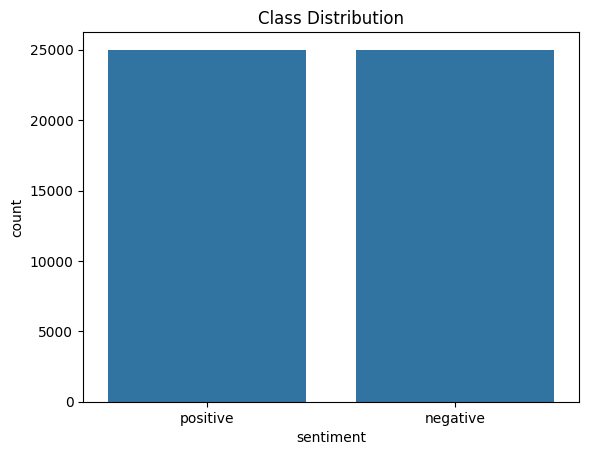

In [16]:
# Class distribution
print(df["sentiment"].value_counts())

sns.countplot(x="sentiment", data=df)
plt.title("Class Distribution")
plt.show()

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: length, dtype: float64


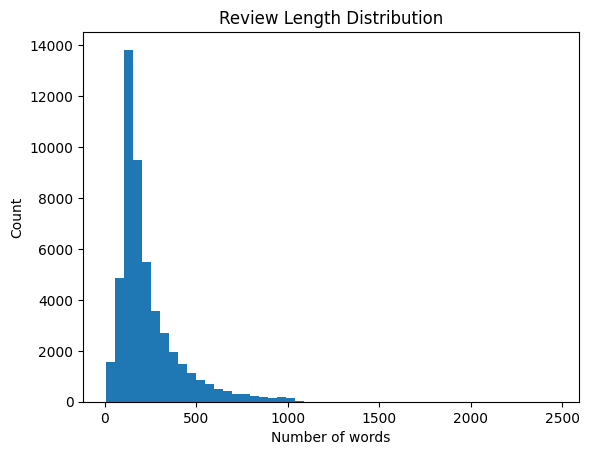

In [17]:
# Review length (number of words)
df["length"] = df["review"].apply(lambda x: len(x.split()))
print(df["length"].describe())

plt.hist(df["length"], bins=50)
plt.title("Review Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Count")
plt.show()

# **Text Cleaning**

In [18]:
df = df.drop_duplicates().reset_index(drop=True)

def clean_text(text):
    text = text.lower()                        # lowercase
    text = re.sub(r"<.*?>", " ", text)         # remove HTML tags
    text = re.sub(r"[^a-z\s]", "", text)       # keep letters only
    text = re.sub(r"\s+", " ", text).strip()   # remove extra spaces
    return text

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

print("Before:", df["review"][0][:150])
print("After :", df["clean_review"][0][:150])

Before: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with
After : one of the other reviewers has mentioned that after watching just oz episode youll be hooked they are right as this is exactly what happened with me t


# **Splitting the Data (Train / Validation / Test)**

In [19]:
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"])

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 34707
Validation: 7437
Test: 7438


# **Tokenization**

In [20]:
def tokenize(text):
    return text.split()

# Count words in the training set only
counter = Counter()
for text in train_df["clean_review"]:
    counter.update(tokenize(text))

# Build the vocabulary (<PAD> = 0, <UNK> = 1)
VOCAB_SIZE = 10000
vocab = {"<PAD>": 0, "<UNK>": 1}
for i, (word, _) in enumerate(counter.most_common(VOCAB_SIZE - 2), start=2):
    vocab[word] = i

print("Vocabulary size:", len(vocab))

# Convert text to numbers
def encode(text):
    return [vocab.get(word, 1) for word in tokenize(text)]

print(encode("this movie was great"))

Vocabulary size: 10000
[11, 17, 13, 80]


# **Padding**

In [21]:
MAX_LEN = 200

def pad_sequence(seq, max_len=MAX_LEN):
    if len(seq) >= max_len:
        return seq[:max_len]                   # cut long reviews
    return [0] * (max_len - len(seq)) + seq    # pad short reviews

def prepare(data):
    X = np.array([pad_sequence(encode(t)) for t in data["clean_review"]])
    y = data["label"].values
    return X, y

X_train, y_train = prepare(train_df)
X_val, y_val = prepare(val_df)
X_test, y_test = prepare(test_df)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

X_train: (34707, 200)
X_val  : (7437, 200)
X_test : (7438, 200)


# **PyTorch Dataset & DataLoader**

In [22]:
class IMDBDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64

train_loader = DataLoader(IMDBDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(IMDBDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(IMDBDataset(X_test, y_test), batch_size=BATCH_SIZE)

# Check one batch
x_batch, y_batch = next(iter(train_loader))
print("x_batch:", x_batch.shape)
print("y_batch:", y_batch.shape)

x_batch: torch.Size([64, 200])
y_batch: torch.Size([64])
